In [1]:
!pip install ucimlrepo

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

In [3]:
dermatology = fetch_ucirepo(id=33)

X = dermatology.data.features
y = dermatology.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Features shape: (366, 34)
Target shape: (366, 1)


,erythema,scaling,definite-borders,itching,koebner phenomenon,polygonal papules,follicular papules,oral-mucosal involvement,knee elbow involvement,scalp involvement,...,focal hypergranulosis,disappearance of the granular layer,vacuolisation and damage of the basal layer,spongiosis,saw-tooth appearance of retes,follicular horn plug,perifollicular parakeratosis,inflammatory monoluclear infiltrate,band-like infiltrate,age
0,2,2,0,3,0,0,0,0,1,0,...,0,0,0,3,0,0,0,1,0,55.0
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,0,1,0,8.0
2,2,1,2,3,1,3,0,3,0,0,...,2,0,2,3,2,0,0,2,3,26.0
3,2,2,2,0,0,0,0,0,3,2,...,0,3,0,0,0,0,0,3,0,40.0
4,2,3,2,2,2,2,0,2,0,0,...,2,2,3,2,3,0,0,2,3,45.0


In [4]:
df = pd.concat([X, y], axis=1)

df.head()

,erythema,scaling,definite-borders,itching,koebner phenomenon,polygonal papules,follicular papules,oral-mucosal involvement,knee elbow involvement,scalp involvement,...,disappearance of the granular layer,vacuolisation and damage of the basal layer,spongiosis,saw-tooth appearance of retes,follicular horn plug,perifollicular parakeratosis,inflammatory monoluclear infiltrate,band-like infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   erythema                                     366 non-null    int64  
 1   scaling                                      366 non-null    int64  
 2   definite-borders                             366 non-null    int64  
 3   itching                                      366 non-null    int64  
 4   koebner phenomenon                           366 non-null    int64  
 5   polygonal papules                            366 non-null    int64  
 6   follicular papules                           366 non-null    int64  
 7   oral-mucosal involvement                     366 non-null    int64  
 8   knee elbow involvement                       366 non-null    int64  
 9   scalp involvement                            366 non-null    int64  
 10  fa

In [6]:
print(df["class"].value_counts().sort_index())

class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
definite-borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
koebner phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
follicular papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
oral-mucosal involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
knee elbow involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
scalp involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0


In [8]:
df.median(numeric_only=True)

,0
erythema,2.0
scaling,2.0
definite-borders,2.0
itching,1.0
koebner phenomenon,0.0
polygonal papules,0.0
follicular papules,0.0
oral-mucosal involvement,0.0
knee elbow involvement,0.0
scalp involvement,0.0


In [9]:
df.mean(numeric_only=True)

,0
erythema,2.068306
scaling,1.795082
definite-borders,1.549180
itching,1.366120
koebner phenomenon,0.633880
polygonal papules,0.448087
follicular papules,0.166667
oral-mucosal involvement,0.377049
knee elbow involvement,0.614754
scalp involvement,0.519126


In [10]:
df.std(numeric_only=True)

,0
erythema,0.664753
scaling,0.701527
definite-borders,0.907525
itching,1.138299
koebner phenomenon,0.908016
polygonal papules,0.957327
follicular papules,0.570588
oral-mucosal involvement,0.834147
knee elbow involvement,0.982979
scalp involvement,0.905639


In [11]:
df.isnull().sum()

,0
erythema,0
scaling,0
definite-borders,0
itching,0
koebner phenomenon,0
polygonal papules,0
follicular papules,0
oral-mucosal involvement,0
knee elbow involvement,0
scalp involvement,0


In [12]:
print("Number of '?' values:")
print((df == "?").sum().sum())

Number of '?' values:
0


In [13]:
df = df.replace("?", np.nan)

df.isnull().sum()

,0
erythema,0
scaling,0
definite-borders,0
itching,0
koebner phenomenon,0
polygonal papules,0
follicular papules,0
oral-mucosal involvement,0
knee elbow involvement,0
scalp involvement,0


In [14]:
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

In [15]:
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

In [16]:
df = df.fillna(df.median(numeric_only=True))

In [17]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [18]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [19]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (366, 35)


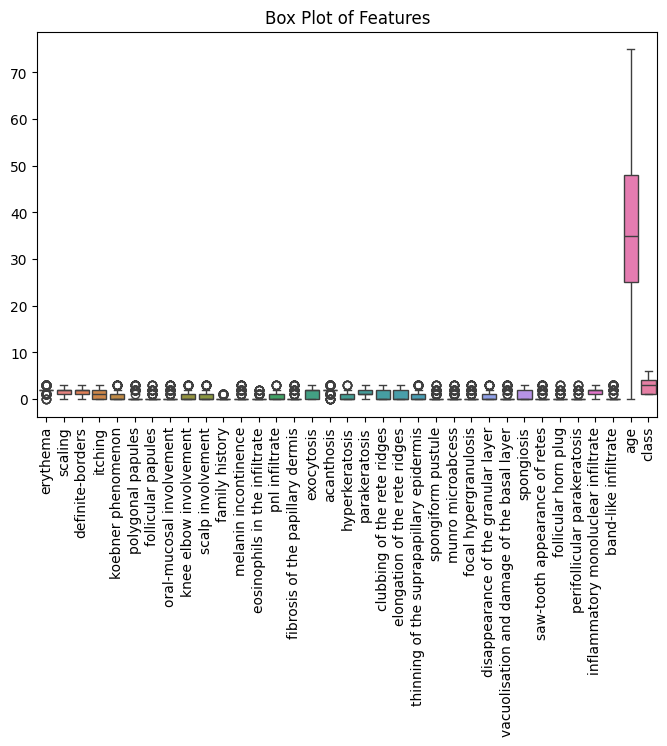

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df)

plt.xticks(rotation=90)
plt.title("Box Plot of Features")
plt.show()

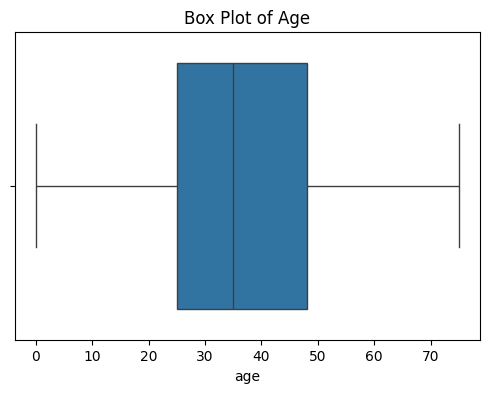

In [21]:
plt.figure(figsize=(6, 4))

sns.boxplot(x=df["age"])

plt.title("Box Plot of Age")
plt.show()

In [22]:
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: -9.5
Upper bound: 82.5


In [23]:
df["age"] = df["age"].clip(lower_bound, upper_bound)

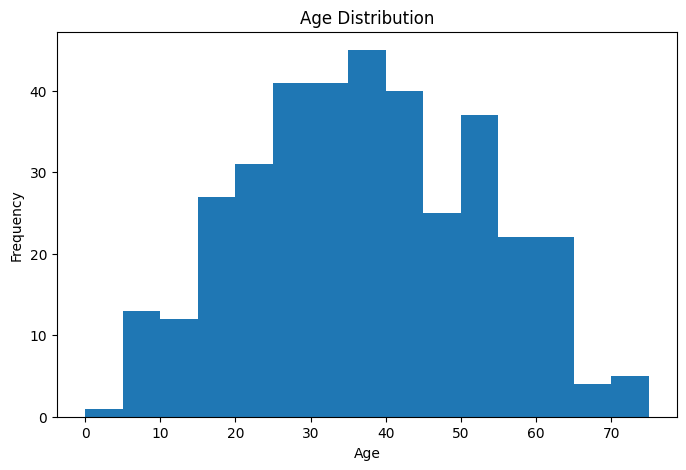

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=15)

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")

plt.show()

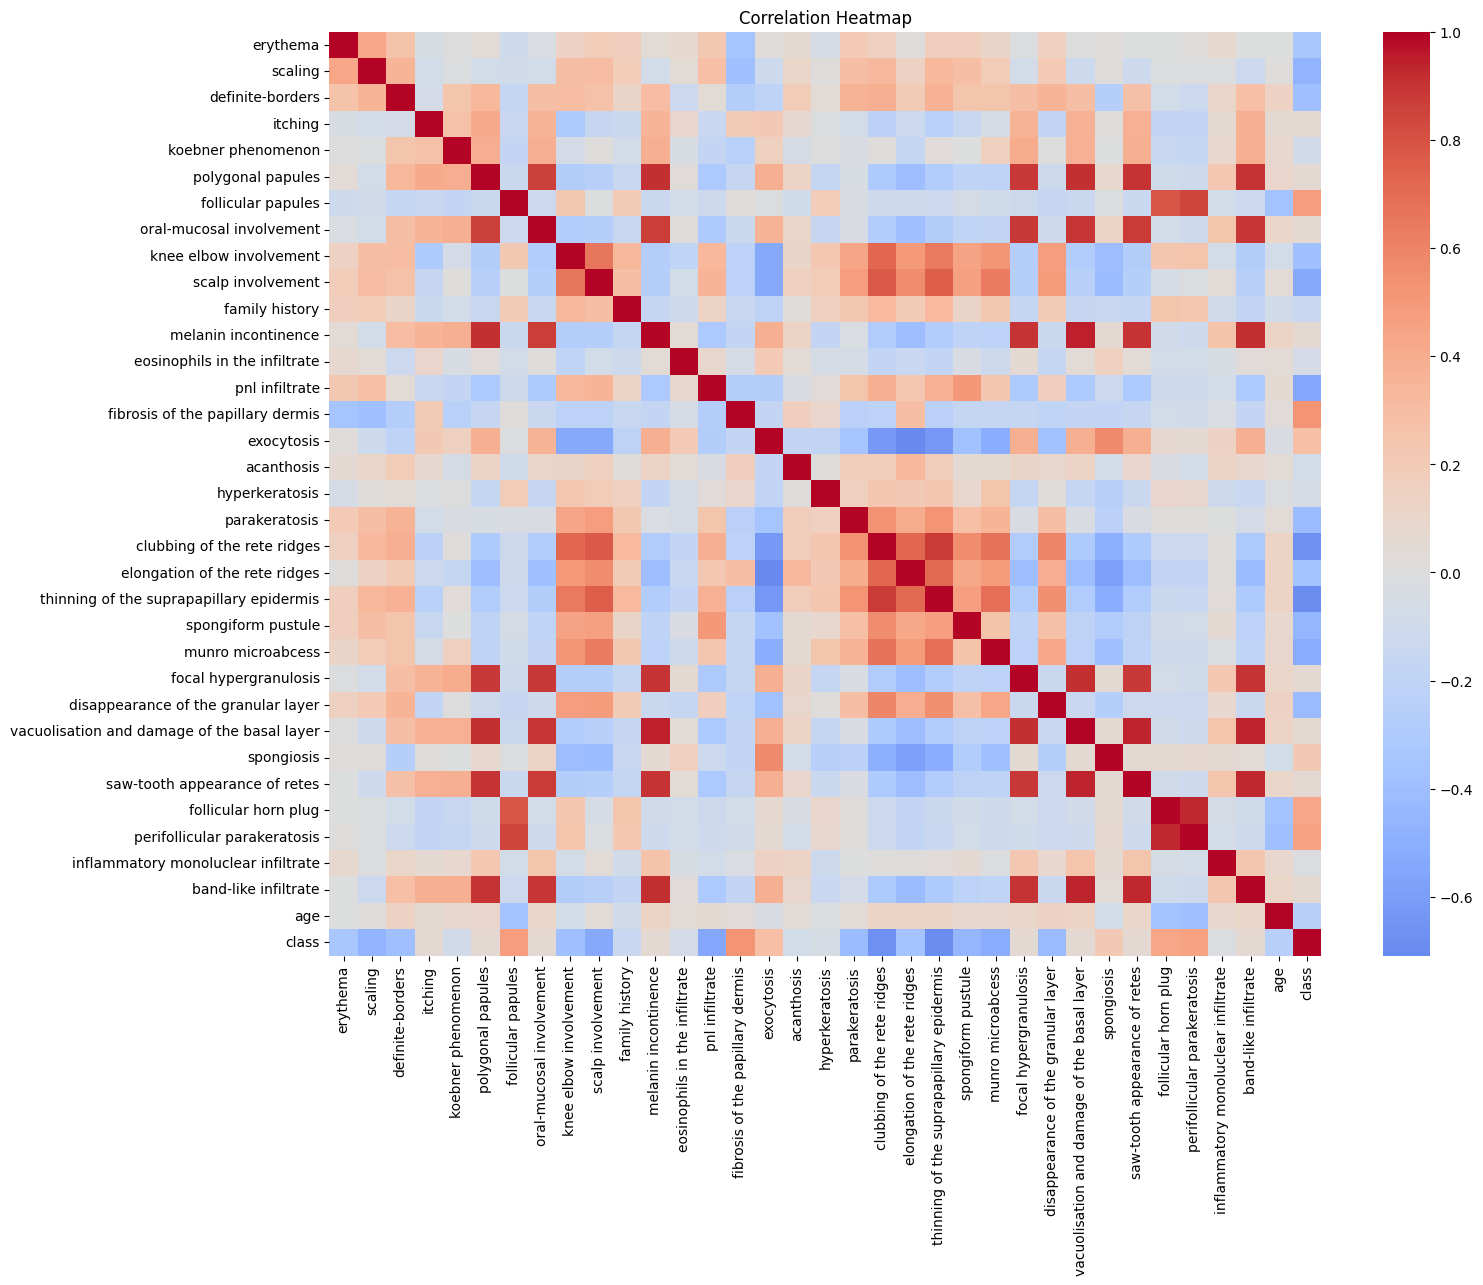

In [25]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

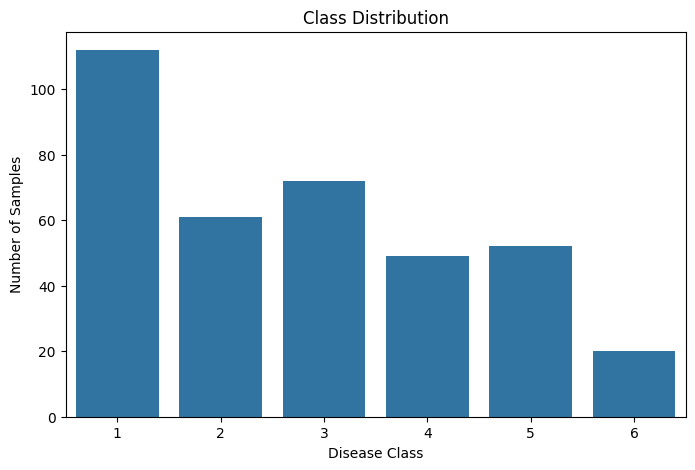

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x="class",
    data=df
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution")

plt.show()

In [27]:
class_counts = df["class"].value_counts().sort_index()

class_percentages = (
    df["class"].value_counts(normalize=True).sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_distribution

,Count,Percentage
class,,
1,112,30.601093
2,61,16.666667
3,72,19.672131
4,49,13.387978
5,52,14.207650
6,20,5.464481


In [28]:
X = df.drop("class", axis=1)
y = df["class"]

In [29]:
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

print("Original classes:", encoder.classes_)
print("Encoded classes:", np.unique(y_encoded))

Original classes: [1 2 3 4 5 6]
Encoded classes: [0 1 2 3 4 5]


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

In [31]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (292, 34)
X_test: (74, 34)
y_train: (292,)
y_test: (74,)


In [32]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [33]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
y_prob_knn = knn.predict_proba(X_test_scaled)

In [34]:
lr = LogisticRegression(
    max_iter=5000,
    multi_class="multinomial"
)

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [35]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)

In [36]:
svm = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)
y_prob_svm = svm.predict_proba(X_test_scaled)

In [37]:
models = {
    "KNN": y_pred_knn,
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "SVM": y_pred_svm
}

accuracy_results = {}

for name, predictions in models.items():
    accuracy_results[name] = accuracy_score(y_test, predictions)

accuracy_results

{'KNN': 0.9054054054054054,
 'Logistic Regression': 0.9594594594594594,
 'Random Forest': 0.9594594594594594,
 'SVM': 0.972972972972973}

In [38]:
for name, predictions in models.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=[
                "Psoriasis",
                "Seboreic Dermatitis",
                "Lichen Planus",
                "Pityriasis Rosea",
                "Cronic Dermatitis",
                "Pityriasis Rubra Pilaris"
            ]
        )
    )


KNN
                          precision    recall  f1-score   support

               Psoriasis       1.00      0.96      0.98        23
     Seboreic Dermatitis       0.80      0.67      0.73        12
           Lichen Planus       1.00      0.93      0.97        15
        Pityriasis Rosea       0.64      0.90      0.75        10
       Cronic Dermatitis       1.00      1.00      1.00        10
Pityriasis Rubra Pilaris       1.00      1.00      1.00         4

                accuracy                           0.91        74
               macro avg       0.91      0.91      0.90        74
            weighted avg       0.92      0.91      0.91        74


Logistic Regression
                          precision    recall  f1-score   support

               Psoriasis       1.00      1.00      1.00        23
     Seboreic Dermatitis       1.00      0.83      0.91        12
           Lichen Planus       1.00      0.93      0.97        15
        Pityriasis Rosea       0.77      1.00 

In [39]:
class_names = [
    "Psoriasis",
    "Seboreic Dermatitis",
    "Lichen Planus",
    "Pityriasis Rosea",
    "Cronic Dermatitis",
    "Pityriasis Rubra Pilaris"
]

In [40]:
def plot_confusion_matrix(y_true, y_pred, model_name):

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.title(f"Confusion Matrix - {model_name}")

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.show()

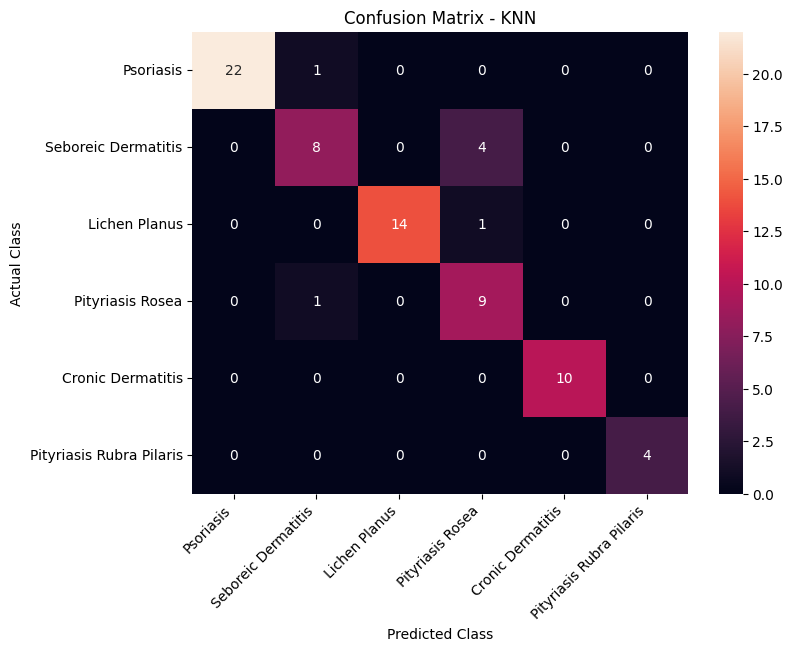

In [41]:
plot_confusion_matrix(
    y_test,
    y_pred_knn,
    "KNN"
)

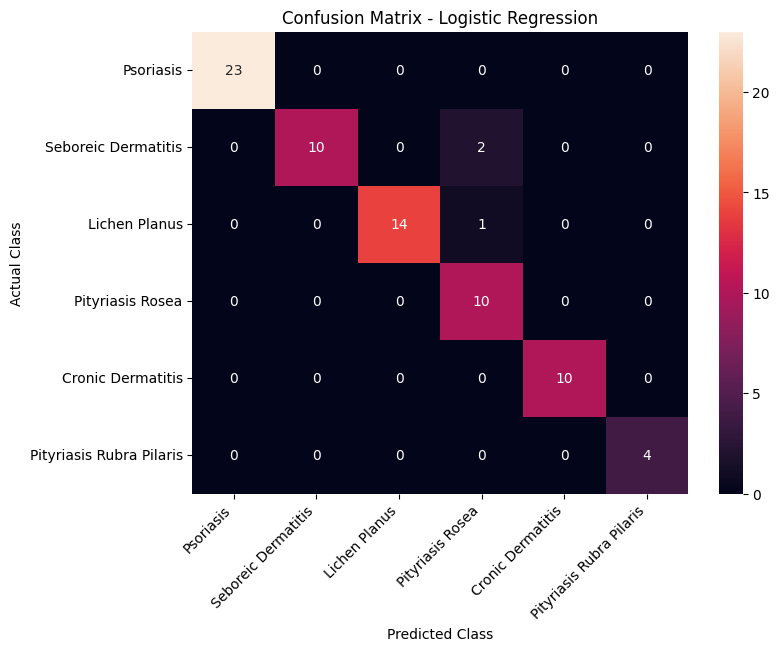

In [42]:
plot_confusion_matrix(
    y_test,
    y_pred_lr,
    "Logistic Regression"
)

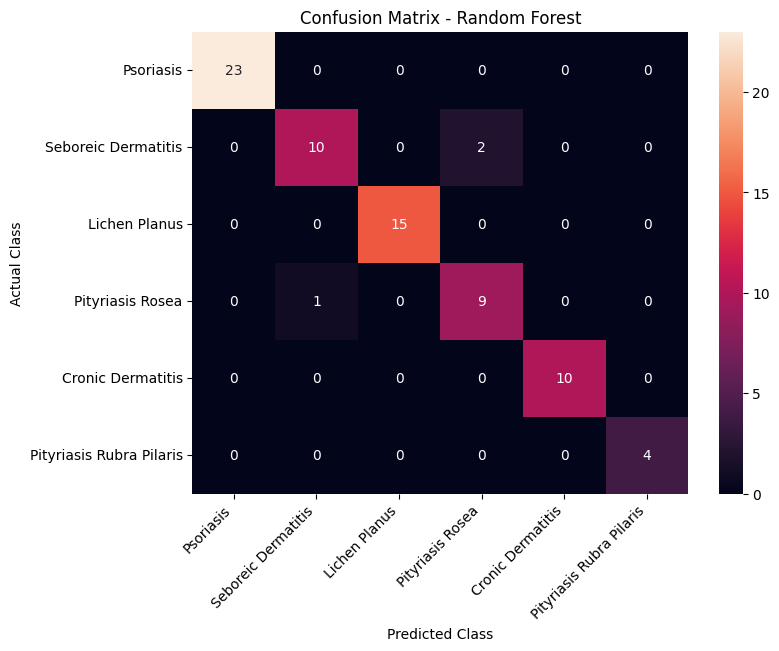

In [43]:
plot_confusion_matrix(
    y_test,
    y_pred_rf,
    "Random Forest"
)

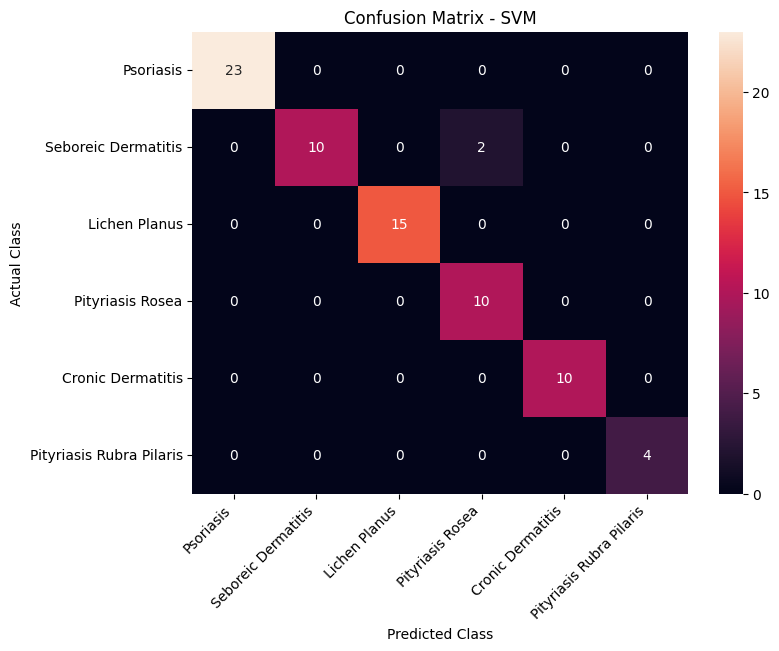

In [44]:
plot_confusion_matrix(
    y_test,
    y_pred_svm,
    "SVM"
)

In [45]:
y_test_binary = label_binarize(
    y_test,
    classes=np.arange(6)
)

In [46]:
def plot_multiclass_roc(y_true, y_prob, model_name):

    fpr = {}
    tpr = {}
    roc_auc = {}

    for i in range(6):

        fpr[i], tpr[i], _ = roc_curve(
            y_true[:, i],
            y_prob[:, i]
        )

        roc_auc[i] = auc(
            fpr[i],
            tpr[i]
        )

    plt.figure(figsize=(9, 7))

    for i in range(6):

        plt.plot(
            fpr[i],
            tpr[i],
            label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(f"Multiclass ROC Curve - {model_name}")

    plt.legend()

    plt.show()

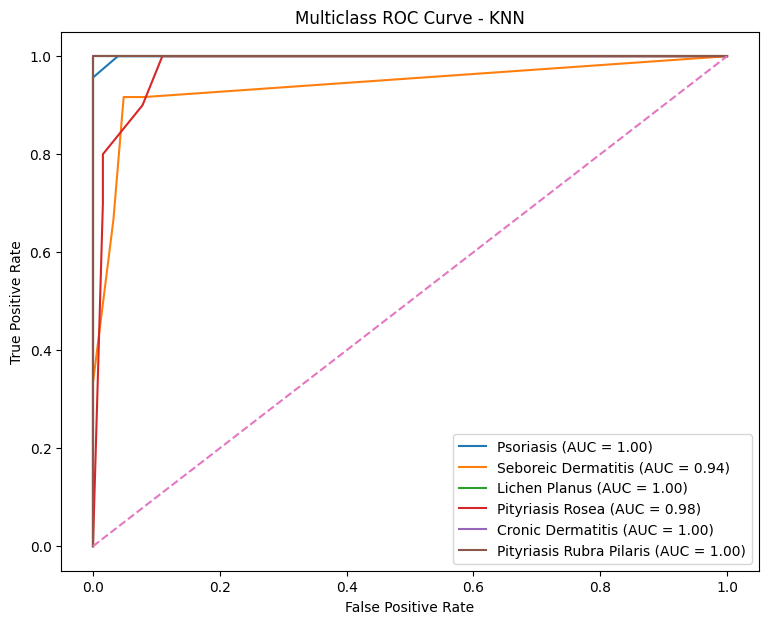

In [47]:
plot_multiclass_roc(
    y_test_binary,
    y_prob_knn,
    "KNN"
)

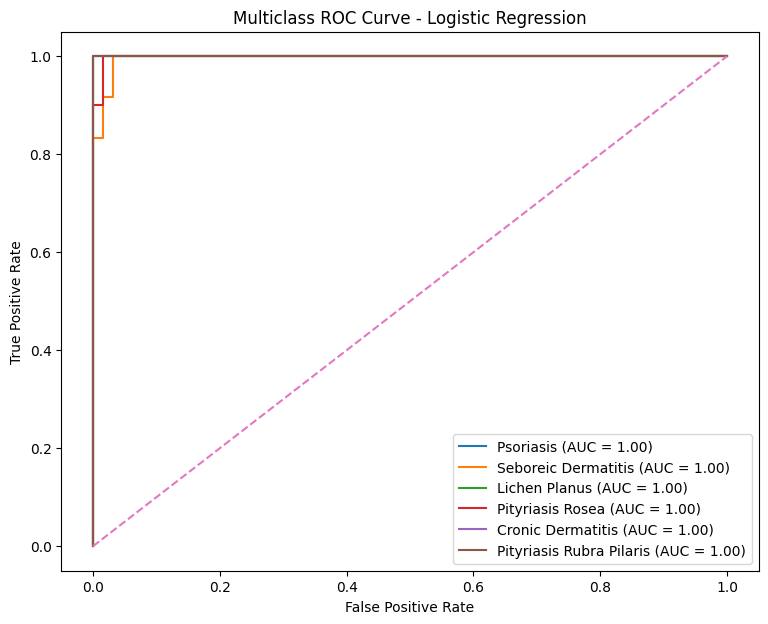

In [48]:
plot_multiclass_roc(
    y_test_binary,
    y_prob_lr,
    "Logistic Regression"
)

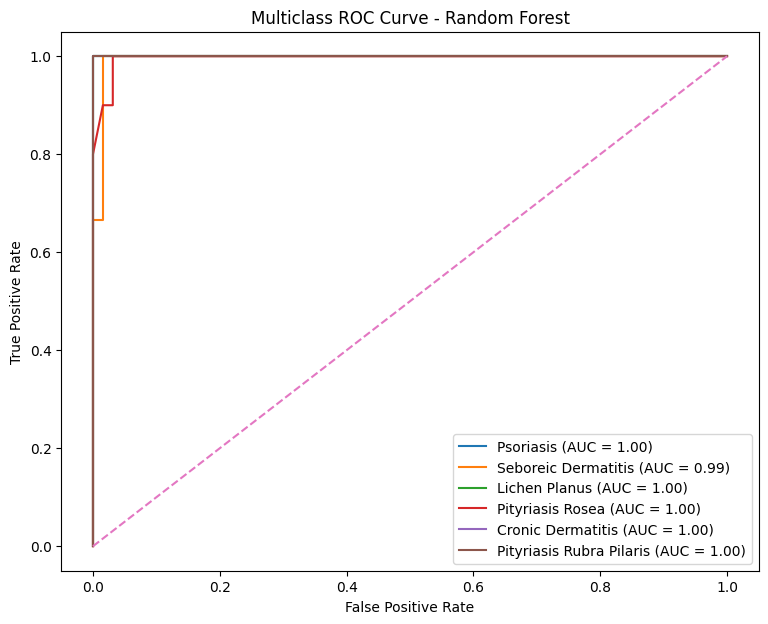

In [49]:
plot_multiclass_roc(
    y_test_binary,
    y_prob_rf,
    "Random Forest"
)

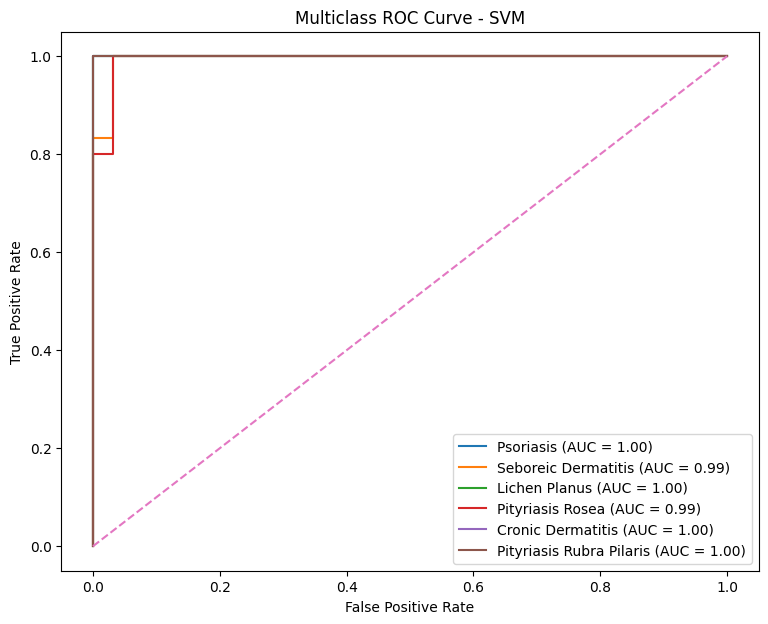

In [50]:
plot_multiclass_roc(
    y_test_binary,
    y_prob_svm,
    "SVM"
)

In [51]:
probabilities = {
    "KNN": y_prob_knn,
    "Logistic Regression": y_prob_lr,
    "Random Forest": y_prob_rf,
    "SVM": y_prob_svm
}

auc_results = {}

for name, probabilities_model in probabilities.items():

    auc_results[name] = roc_auc_score(
        y_test_binary,
        probabilities_model,
        multi_class="ovr",
        average="weighted"
    )

auc_results

{'KNN': np.float64(0.9870763270979708),
 'Logistic Regression': np.float64(0.9991349716652136),
 'Random Forest': np.float64(0.9986002887968614),
 'SVM': np.float64(0.9982835658238884)}

In [52]:
results = []

for name, predictions in models.items():

    if name == "KNN":
        probabilities_model = y_prob_knn

    elif name == "Logistic Regression":
        probabilities_model = y_prob_lr

    elif name == "Random Forest":
        probabilities_model = y_prob_rf

    else:
        probabilities_model = y_prob_svm

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test,
            predictions,
            average="weighted"
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            average="weighted"
        ),
        "F1 Score": f1_score(
            y_test,
            predictions,
            average="weighted"
        ),
        "ROC-AUC": roc_auc_score(
            y_test_binary,
            probabilities_model,
            multi_class="ovr",
            average="weighted"
        )
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,KNN,0.905405,0.919305,0.905405,0.908094,0.987076
1,Logistic Regression,0.959459,0.968815,0.959459,0.960642,0.999135
2,Random Forest,0.959459,0.960688,0.959459,0.959543,0.998600
3,SVM,0.972973,0.977477,0.972973,0.972973,0.998284


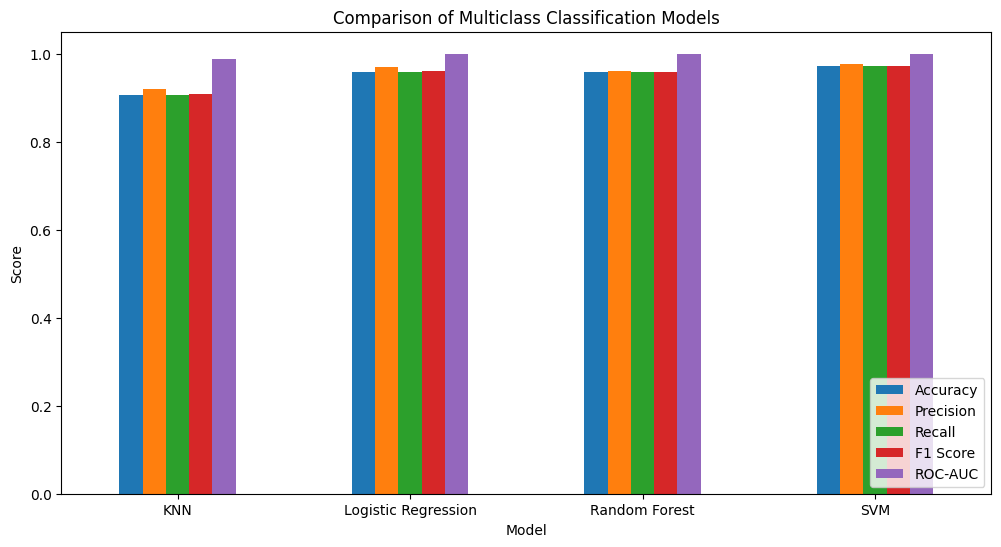

In [53]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.ylabel("Score")
plt.title("Comparison of Multiclass Classification Models")

plt.xticks(rotation=0)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")

plt.show()